<a href="https://colab.research.google.com/github/SubhashreePal/DL-group-3-plant-leaf-disease-classification/blob/master/DL_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kagglehub split-folders

In [ ]:
import os
import shutil
import random
import time
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


In [ ]:
print("Contents of dataset:")
print(os.listdir(path))

Contents of dataset:
['PlantVillage', 'plantvillage']


In [ ]:
for root, dirs, files in os.walk(path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Number of files:", len(files))
    print("-" * 60)

Folder: /kaggle/input/plantdisease
Subfolders: ['PlantVillage', 'plantvillage']
Number of files: 0
------------------------------------------------------------
Folder: /kaggle/input/plantdisease/PlantVillage
Subfolders: ['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot']
Number of files: 0
------------------------------------------------------------
Folder: /kaggle/input/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot
Subfolders: []
Number of files: 997
------------------------------------------------------------
Folder: /kaggle/input/plantdisease/PlantVillage/Potato___healthy
Subfolders: []
Number of files: 152
------------------------------------------------------------
Folder: /kaggle/input/plantdisease/PlantVillage/Tomato_Leaf_Mold
Subfolders: []
Num

In [ ]:
# Find directories that contain image files
image_extensions = (".jpg", ".jpeg", ".png")

candidate_dirs = []

for root, dirs, files in os.walk(path):
    image_count = sum(
        file.lower().endswith(image_extensions)
        for file in files
    )

    if image_count > 0:
        candidate_dirs.append((root, image_count))

candidate_dirs[:10]

[('/kaggle/input/plantdisease/PlantVillage/Pepper__bell___Bacterial_spot',
  997),
 ('/kaggle/input/plantdisease/PlantVillage/Potato___healthy', 152),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_Leaf_Mold', 952),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus',
  3208),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_Bacterial_spot', 2127),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot', 1771),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_healthy', 1591),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite',
  1676),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato_Early_blight', 1000),
 ('/kaggle/input/plantdisease/PlantVillage/Tomato__Target_Spot', 1404)]

In [ ]:
class_names = sorted(list(set([
    os.path.basename(folder_path)
    for folder_path, _ in candidate_dirs
])))

print("Number of classes:", len(class_names))
print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 15

Classes:
0 : Pepper__bell___Bacterial_spot
1 : Pepper__bell___healthy
2 : Potato___Early_blight
3 : Potato___Late_blight
4 : Potato___healthy
5 : Tomato_Bacterial_spot
6 : Tomato_Early_blight
7 : Tomato_Late_blight
8 : Tomato_Leaf_Mold
9 : Tomato_Septoria_leaf_spot
10 : Tomato_Spider_mites_Two_spotted_spider_mite
11 : Tomato__Target_Spot
12 : Tomato__Tomato_YellowLeaf__Curl_Virus
13 : Tomato__Tomato_mosaic_virus
14 : Tomato_healthy


In [ ]:
class_counts = {}

for folder_path, count in candidate_dirs:
    class_name = os.path.basename(folder_path)
    class_counts[class_name] = count

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

class_counts_df

,Class,Images
0,Pepper__bell___Bacterial_spot,997
1,Potato___healthy,152
2,Tomato_Leaf_Mold,952
3,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
4,Tomato_Bacterial_spot,2127
5,Tomato_Septoria_leaf_spot,1771
6,Tomato_healthy,1591
7,Tomato_Spider_mites_Two_spotted_spider_mite,1676
8,Tomato_Early_blight,1000
9,Tomato__Target_Spot,1404


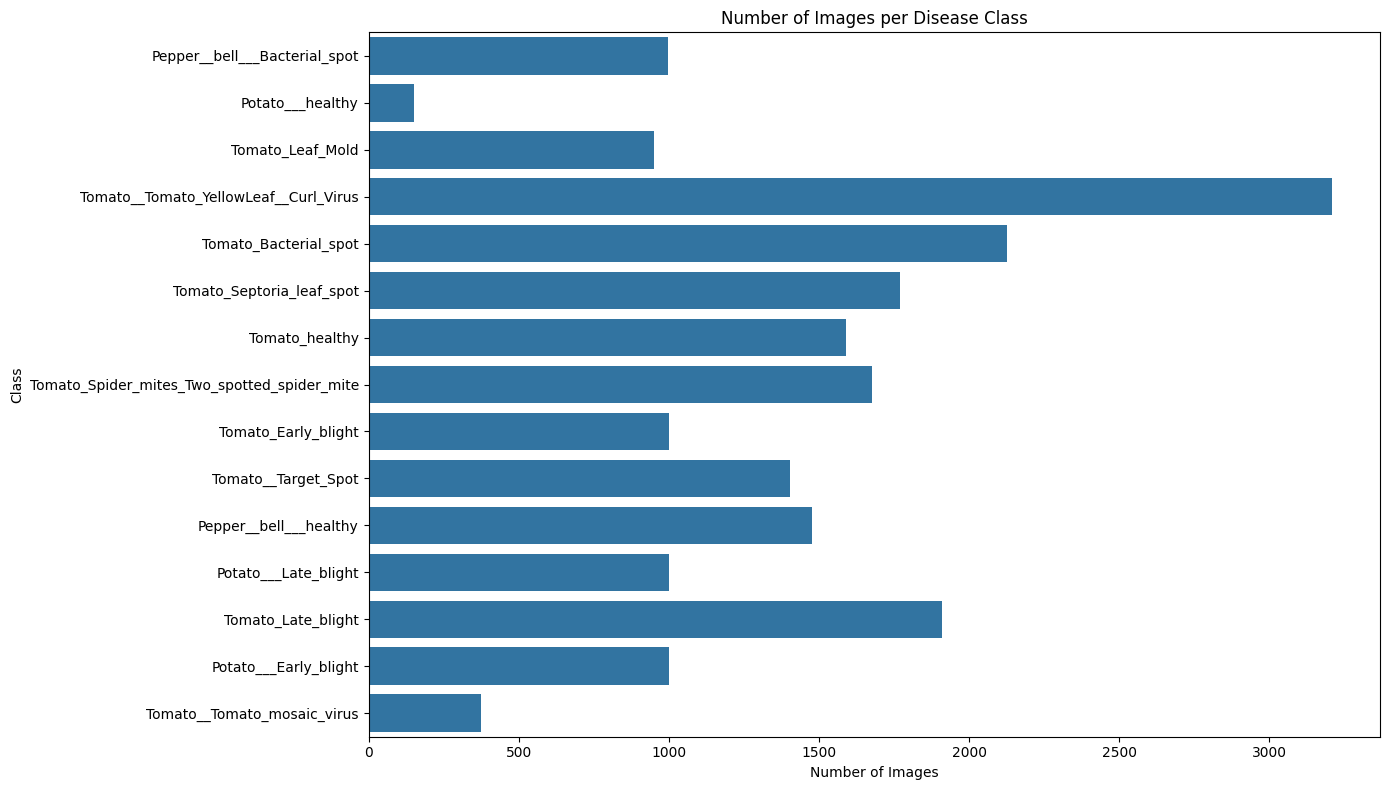

In [ ]:
plt.figure(figsize=(14, 8))

sns.barplot(
    data=class_counts_df,
    x="Images",
    y="Class"
)

plt.title("Number of Images per Disease Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

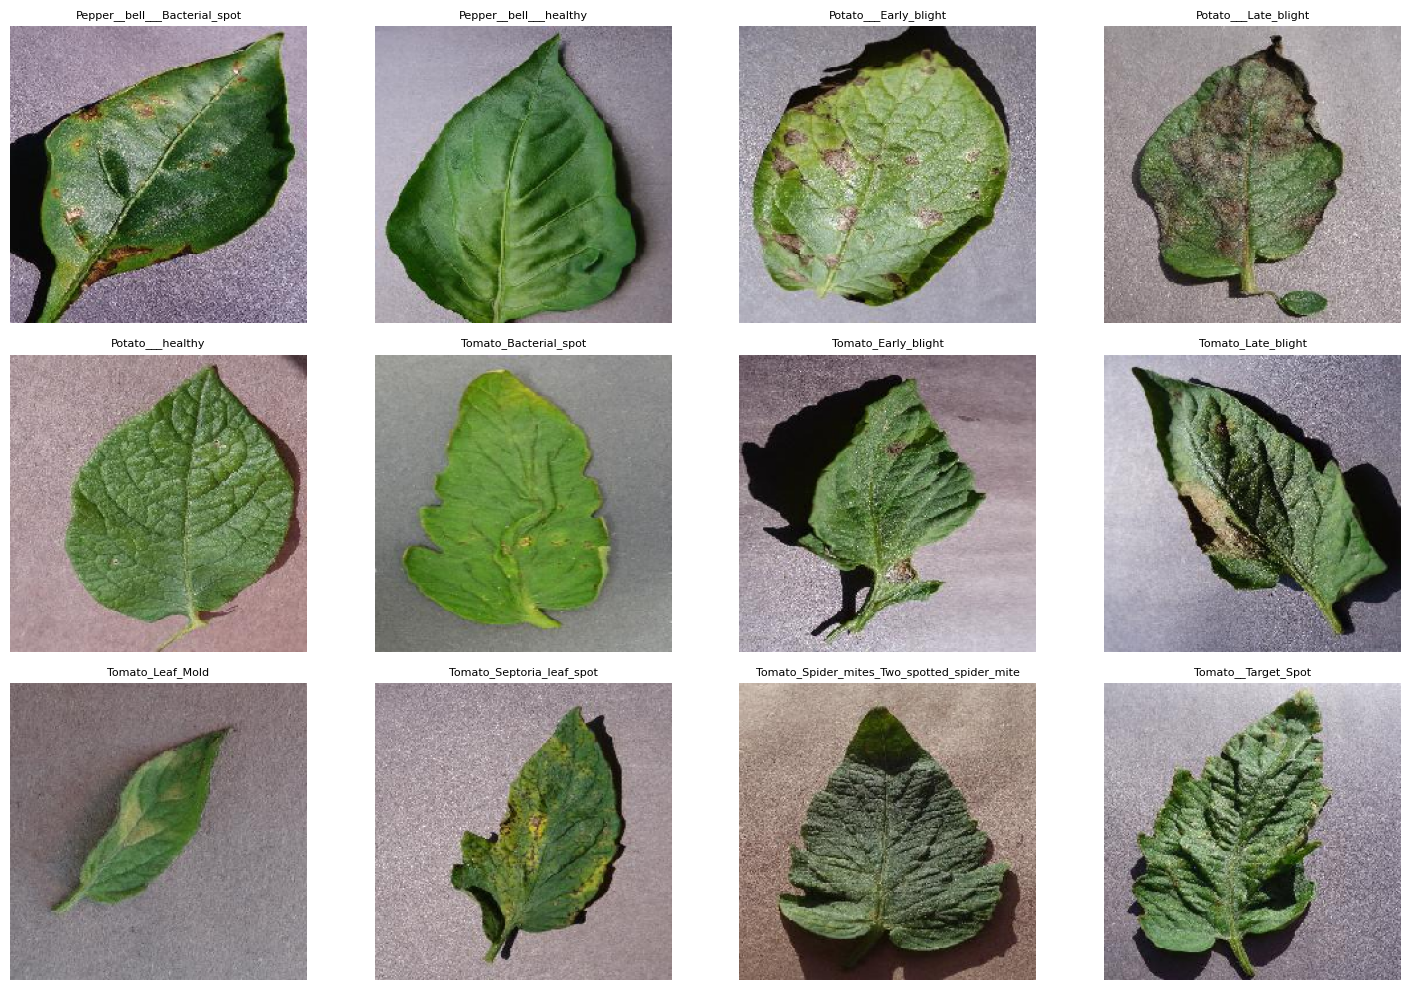

In [ ]:
class_name_to_path_map = {os.path.basename(folder_path): folder_path for folder_path, _ in candidate_dirs}

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(class_names[:12]):

    class_path = class_name_to_path_map[class_name]

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Only proceed if there are images in the directory
    if images:
        image_path = os.path.join(
            class_path,
            random.choice(images)
        )

        image = tf.keras.utils.load_img(
            image_path,
            target_size=(224, 224)
        )

        plt.subplot(3, 4, i + 1)
        plt.imshow(image)
        plt.title(class_name, fontsize=8)
        plt.axis("off")
    else:
        print(f"No images found for class: {class_name}. Skipping.")

plt.tight_layout()
plt.show()

In [ ]:
import splitfolders

DATASET_DIR = os.path.join(path, "PlantVillage")
SPLIT_DIR = "/content/PlantDisease_Split"

splitfolders.ratio(
    DATASET_DIR,
    output=SPLIT_DIR,
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

Copying files: 20639 files [01:27, 236.63 files/s]


In [ ]:
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR = os.path.join(SPLIT_DIR, "val")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

Train: /content/PlantDisease_Split/train
Validation: /content/PlantDisease_Split/val
Test: /content/PlantDisease_Split/test


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", NUM_CLASSES)

Found 14440 files belonging to 15 classes.
Found 3089 files belonging to 15 classes.
Found 3109 files belonging to 15 classes.
Classes: 15


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
data_augmentation = keras.Sequential([

    # Geometric augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.10, 0.10),

    # Colour augmentation
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),

], name="data_augmentation")

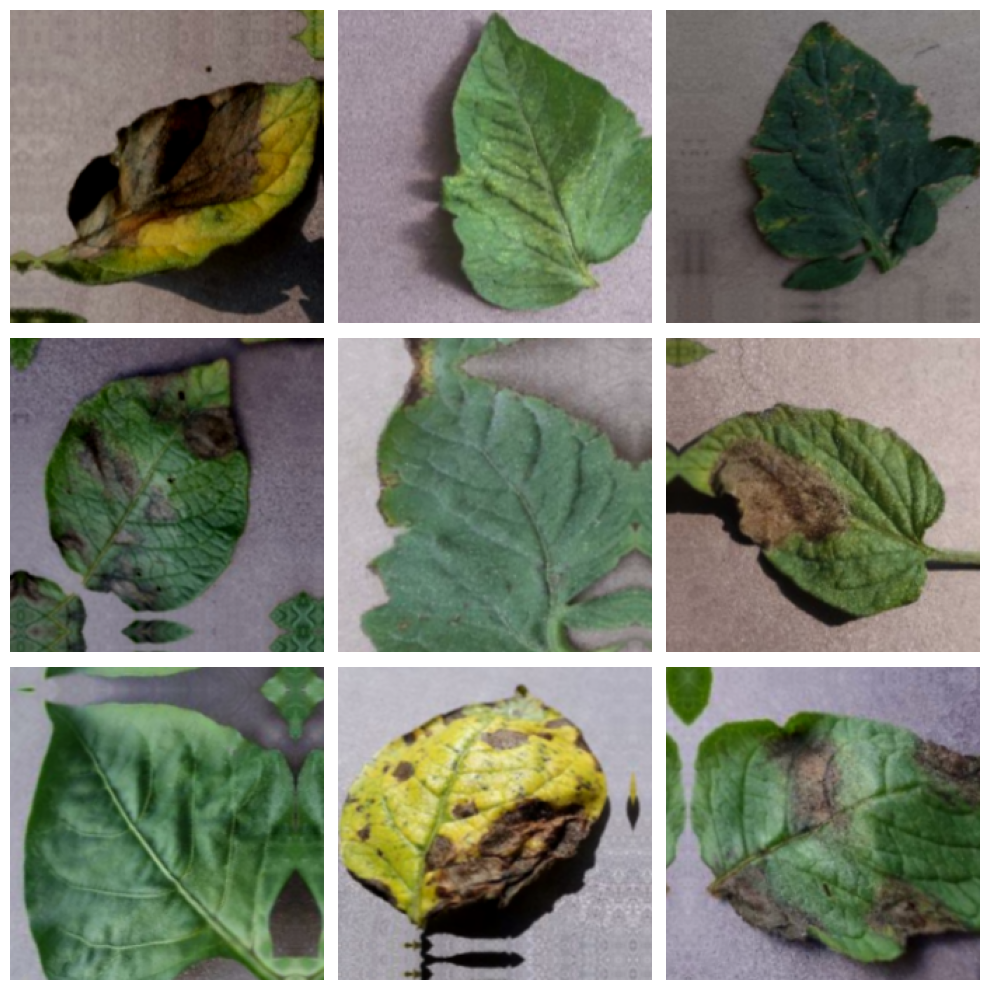

In [ ]:
for images, labels in train_ds.take(1):
    sample_images = images[:9]

plt.figure(figsize=(10, 10))

for i in range(9):
    augmented = data_augmentation(
        tf.expand_dims(sample_images[i], 0),
        training=True
    )

    plt.subplot(3, 3, i + 1)
    plt.imshow(tf.cast(augmented[0], tf.uint8))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

In [ ]:
def build_cnn_from_scratch():

    inputs = keras.Input(
        shape=(224, 224, 3)
    )

    x = data_augmentation(inputs)

    x = layers.Rescaling(1./255)(x)

    # Block 1
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 2
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 3
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # Block 4
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(inputs, outputs)

    return model

In [ ]:
cnn_model = build_cnn_from_scratch()

cnn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 459,983 (1.75 MB)

 Trainable params: 459,023 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
start_time = time.time()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

cnn_training_time = time.time() - start_time

print(
    f"Training time: {cnn_training_time / 60:.2f} minutes"
)

Epoch 1/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 70s 136ms/step - accuracy: 0.5983 - loss: 1.2279 - val_accuracy: 0.1670 - val_loss: 5.3770 - learning_rate: 0.0010
Epoch 2/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 79s 141ms/step - accuracy: 0.7584 - loss: 0.7318 - val_accuracy: 0.6102 - val_loss: 1.2288 - learning_rate: 0.0010
Epoch 3/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 64s 142ms/step - accuracy: 0.8298 - loss: 0.5130 - val_accuracy: 0.3315 - val_loss: 4.6304 - learning_rate: 0.0010
Epoch 4/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 63s 139ms/step - accuracy: 0.8654 - loss: 0.4117 - val_accuracy: 0.4833 - val_loss: 2.1967 - learning_rate: 0.0010
Epoch 5/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 63s 140ms/step - accuracy: 0.9150 - loss: 0.2665 - val_accuracy: 0.8867 - val_loss: 0.3488 - learning_rate: 2.0000e-04
Epoch 6/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 64s 141ms/step - accuracy: 0.9290 - loss: 0.2221 - val_accuracy: 0.8440 - val_loss: 0.5138 - learning_rate: 2.0000e-04
Epoch 7/20
452/452 ━━━━━━━━━━━━━━━━━━━━ 67s 147ms/step - accur

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    test_ds
)

print("CNN Test Accuracy:", cnn_test_accuracy)

98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.9218 - loss: 0.2032
CNN Test Accuracy: 0.9218398332595825


In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [ ]:
def build_vgg16():

    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze entire pretrained base
    base_model.trainable = False

    inputs = keras.Input(
        shape=(224, 224, 3)
    )

    x = data_augmentation(inputs)

    x = preprocess_input(x)

    x = base_model(
        x,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    return model, base_model

In [ ]:
vgg_model, vgg_base = build_vgg16()

vgg_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 15)        │      3,855 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,849,871 (56.65 MB)

 Trainable params: 135,183 (528.06 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
start_time = time.time()

vgg_history = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

vgg_training_time = time.time() - start_time

print(
    f"Training time: {vgg_training_time / 60:.2f} minutes"
)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 78s 173ms/step - accuracy: 0.7480 - loss: 0.7780 - val_accuracy: 0.8297 - val_loss: 0.5367 - learning_rate: 4.0000e-05
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 80s 177ms/step - accuracy: 0.7652 - loss: 0.7183 - val_accuracy: 0.8378 - val_loss: 0.5176 - learning_rate: 4.0000e-05
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 85s 188ms/step - accuracy: 0.7725 - loss: 0.7060 - val_accuracy: 0.8359 - val_loss: 0.5160 - learning_rate: 8.0000e-06
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.7733 - loss: 0.6966 - val_accuracy: 0.8381 - val_loss: 0.5144 - learning_rate: 8.0000e-06
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 80s 177ms/step - accuracy: 0.7747 - loss: 0.6954 - val_accuracy: 0.8385 - val_loss: 0.5147 - learning_rate: 1.6000e-06
Training time: 7.64 minutes


In [ ]:
# Keep early layers frozen
for layer in vgg_base.layers:
    layer.trainable = False

# Unfreeze the last convolutional block
for layer in vgg_base.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True

In [ ]:
trainable_count = sum(
    layer.trainable
    for layer in vgg_base.layers
)

print("Trainable VGG16 base layers:", trainable_count)

Trainable VGG16 base layers: 4


In [ ]:
trainable_count = sum(
    layer.trainable
    for layer in vgg_base.layers
)

print("Trainable VGG16 base layers:", trainable_count)

Trainable VGG16 base layers: 4


In [ ]:
start_time = time.time()

vgg_finetune_history = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

vgg_finetune_time = time.time() - start_time

print(
    f"VGG16 fine-tuning time: "
    f"{vgg_finetune_time / 60:.2f} minutes"
)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 77s 171ms/step - accuracy: 0.7556 - loss: 0.7490 - val_accuracy: 0.8294 - val_loss: 0.5371 - learning_rate: 1.6000e-06
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 81s 179ms/step - accuracy: 0.7529 - loss: 0.7556 - val_accuracy: 0.8304 - val_loss: 0.5369 - learning_rate: 1.6000e-06
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 87s 193ms/step - accuracy: 0.7618 - loss: 0.7312 - val_accuracy: 0.8304 - val_loss: 0.5367 - learning_rate: 3.2000e-07
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 84s 186ms/step - accuracy: 0.7616 - loss: 0.7386 - val_accuracy: 0.8307 - val_loss: 0.5365 - learning_rate: 3.2000e-07
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 90s 199ms/step - accuracy: 0.7641 - loss: 0.7363 - val_accuracy: 0.8307 - val_loss: 0.5365 - learning_rate: 1.0000e-07
VGG16 fine-tuning time: 6.99 minutes


In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

In [ ]:
def build_resnet50():

    base_model = ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    inputs = keras.Input(
        shape=(224, 224, 3)
    )

    x = data_augmentation(inputs)

    x = preprocess_input(x)

    x = base_model(
        x,
        training=False
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        256,
        activation="relu"
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs,
        outputs
    )

    return model, base_model

In [ ]:
resnet_model, resnet_base = build_resnet50()

resnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_5[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 15)        │      3,855 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,116,111 (92.00 MB)

 Trainable params: 528,399 (2.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
start_time = time.time()

resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

resnet_training_time = time.time() - start_time

print(
    f"Training time: "
    f"{resnet_training_time / 60:.2f} minutes"
)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 96s 191ms/step - accuracy: 0.7327 - loss: 0.8356 - val_accuracy: 0.8440 - val_loss: 0.4397 - learning_rate: 0.0010
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 77s 169ms/step - accuracy: 0.8539 - loss: 0.4351 - val_accuracy: 0.8601 - val_loss: 0.4183 - learning_rate: 0.0010
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 78s 173ms/step - accuracy: 0.8985 - loss: 0.3056 - val_accuracy: 0.8835 - val_loss: 0.3423 - learning_rate: 2.0000e-04
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 83s 176ms/step - accuracy: 0.9091 - loss: 0.2746 - val_accuracy: 0.8928 - val_loss: 0.3133 - learning_rate: 2.0000e-04
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 79s 175ms/step - accuracy: 0.9161 - loss: 0.2476 - val_accuracy: 0.8993 - val_loss: 0.2899 - learning_rate: 4.0000e-05
Training time: 6.93 minutes


In [ ]:
# Freeze everything first
for layer in resnet_base.layers:
    layer.trainable = False

# Unfreeze the last ~30 layers
for layer in resnet_base.layers[-30:]:
    layer.trainable = True

In [ ]:
trainable_count = sum(
    layer.trainable
    for layer in resnet_base.layers
)

print(
    "Trainable ResNet50 base layers:",
    trainable_count
)

Trainable ResNet50 base layers: 30


In [ ]:
resnet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
start_time = time.time()

resnet_finetune_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

resnet_finetune_time = time.time() - start_time

print(
    f"ResNet50 fine-tuning time: "
    f"{resnet_finetune_time / 60:.2f} minutes"
)

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 115s 224ms/step - accuracy: 0.8035 - loss: 0.6111 - val_accuracy: 0.8721 - val_loss: 0.3751 - learning_rate: 1.0000e-05
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 102s 226ms/step - accuracy: 0.8986 - loss: 0.3159 - val_accuracy: 0.9094 - val_loss: 0.2580 - learning_rate: 1.0000e-05
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 105s 232ms/step - accuracy: 0.9127 - loss: 0.2687 - val_accuracy: 0.9152 - val_loss: 0.2453 - learning_rate: 2.0000e-06
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 143s 234ms/step - accuracy: 0.9221 - loss: 0.2477 - val_accuracy: 0.9181 - val_loss: 0.2365 - learning_rate: 2.0000e-06
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 104s 229ms/step - accuracy: 0.9235 - loss: 0.2390 - val_accuracy: 0.9233 - val_loss: 0.2197 - learning_rate: 2.0000e-06
Epoch 6/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 103s 228ms/step - accuracy: 0.9280 - loss: 0.2258 - val_accuracy: 0.9255 - val_loss: 0.2114 - learning_rate: 2.0000e-06
Epoch 7/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
def evaluate_model(model, dataset, model_name):

    y_true = []
    y_pred = []

    for images, labels in dataset:

        predictions = model.predict(
            images,
            verbose=0
        )

        predictions = np.argmax(
            predictions,
            axis=1
        )

        y_true.extend(labels.numpy())
        y_pred.extend(predictions)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    print(f"\n{model_name}")
    print("-" * 50)
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "y_true": y_true,
        "y_pred": y_pred
    }

In [ ]:
cnn_results = evaluate_model(
    cnn_model,
    test_ds,
    "CNN From Scratch"
)

vgg_results = evaluate_model(
    vgg_model,
    test_ds,
    "VGG16 Fine-tuned"
)

resnet_results = evaluate_model(
    resnet_model,
    test_ds,
    "ResNet50 Fine-tuned"
)


CNN From Scratch
--------------------------------------------------
Accuracy : 0.9218398198777742
Precision: 0.9304393326778345
Recall   : 0.9218398198777742
F1 Score : 0.9224298876067905

VGG16 Fine-tuned
--------------------------------------------------
Accuracy : 0.8417497587648761
Precision: 0.8523897257678694
Recall   : 0.8417497587648761
F1 Score : 0.831881337218809

ResNet50 Fine-tuned
--------------------------------------------------
Accuracy : 0.9498230942425218
Precision: 0.9516704117588445
Recall   : 0.9498230942425218
F1 Score : 0.9490037668634963


In [ ]:
results_df = pd.DataFrame([
    {
        "Model": "CNN From Scratch",
        "Accuracy": cnn_results["Accuracy"],
        "Precision": cnn_results["Precision"],
        "Recall": cnn_results["Recall"],
        "F1 Score": cnn_results["F1 Score"],
        "Training Time (min)": cnn_training_time / 60
    },

    {
        "Model": "VGG16",
        "Accuracy": vgg_results["Accuracy"],
        "Precision": vgg_results["Precision"],
        "Recall": vgg_results["Recall"],
        "F1 Score": vgg_results["F1 Score"],
        "Training Time (min)":
            (vgg_training_time + vgg_finetune_time) / 60
    },

    {
        "Model": "ResNet50",
        "Accuracy": resnet_results["Accuracy"],
        "Precision": resnet_results["Precision"],
        "Recall": resnet_results["Recall"],
        "F1 Score": resnet_results["F1 Score"],
        "Training Time (min)":
            (resnet_training_time + resnet_finetune_time) / 60
    }
])

results_df

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (min)
0,CNN From Scratch,0.921840,0.930439,0.921840,0.922430,18.694217
1,VGG16,0.841750,0.852390,0.841750,0.831881,14.633910
2,ResNet50,0.949823,0.951670,0.949823,0.949004,25.381277


In [ ]:
def model_parameters(model):

    total = model.count_params()

    trainable = np.sum([
        np.prod(v.shape)
        for v in model.trainable_weights
    ])

    non_trainable = total - trainable

    return total, trainable, non_trainable

In [ ]:
models = {
    "CNN From Scratch": cnn_model,
    "VGG16": vgg_model,
    "ResNet50": resnet_model
}

parameter_results = []

for name, model in models.items():

    total, trainable, non_trainable = \
        model_parameters(model)

    parameter_results.append({
        "Model": name,
        "Total Parameters": total,
        "Trainable Parameters": trainable,
        "Non-trainable Parameters": non_trainable
    })

parameter_df = pd.DataFrame(parameter_results)

parameter_df

,Model,Total Parameters,Trainable Parameters,Non-trainable Parameters
0,CNN From Scratch,459983,459023,960
1,VGG16,14849871,7214607,7635264
2,ResNet50,24116111,14978575,9137536


In [ ]:
models = {
    "CNN From Scratch": cnn_model,
    "VGG16": vgg_model,
    "ResNet50": resnet_model
}

parameter_results = []

for name, model in models.items():

    total, trainable, non_trainable = \
        model_parameters(model)

    parameter_results.append({
        "Model": name,
        "Total Parameters": total,
        "Trainable Parameters": trainable,
        "Non-trainable Parameters": non_trainable
    })

parameter_df = pd.DataFrame(parameter_results)

parameter_df

,Model,Total Parameters,Trainable Parameters,Non-trainable Parameters
0,CNN From Scratch,459983,459023,960
1,VGG16,14849871,7214607,7635264
2,ResNet50,24116111,14978575,9137536


In [ ]:
def get_file_size_mb(path):

    size_bytes = os.path.getsize(path)

    return size_bytes / (1024 ** 2)


# Define paths to save models
cnn_path = "cnn_model.keras"
vgg_path = "vgg_model.keras"
resnet_path = "resnet_model.keras"

# Save the models
cnn_model.save(cnn_path)
vgg_model.save(vgg_path)
resnet_model.save(resnet_path)

size_results = pd.DataFrame([
    {
        "Model": "CNN From Scratch",
        "Model Size (MB)": get_file_size_mb(cnn_path)
    },
    {
        "Model": "VGG16",
        "Model Size (MB)": get_file_size_mb(vgg_path)
    },
    {
        "Model": "ResNet50",
        "Model Size (MB)": get_file_size_mb(resnet_path)
    }
])

size_results

,Model,Model Size (MB)
0,CNN From Scratch,5.355974
1,VGG16,57.789865
2,ResNet50,206.949823


In [ ]:
final_comparison = results_df.merge(
    parameter_df,
    on="Model"
).merge(
    size_results,
    on="Model"
)

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (min),Total Parameters,Trainable Parameters,Non-trainable Parameters,Model Size (MB)
0,CNN From Scratch,0.921840,0.930439,0.921840,0.922430,18.694217,459983,459023,960,5.355974
1,VGG16,0.841750,0.852390,0.841750,0.831881,14.633910,14849871,7214607,7635264,57.789865
2,ResNet50,0.949823,0.951670,0.949823,0.949004,25.381277,24116111,14978575,9137536,206.949823


In [ ]:
def plot_history(history, title):

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

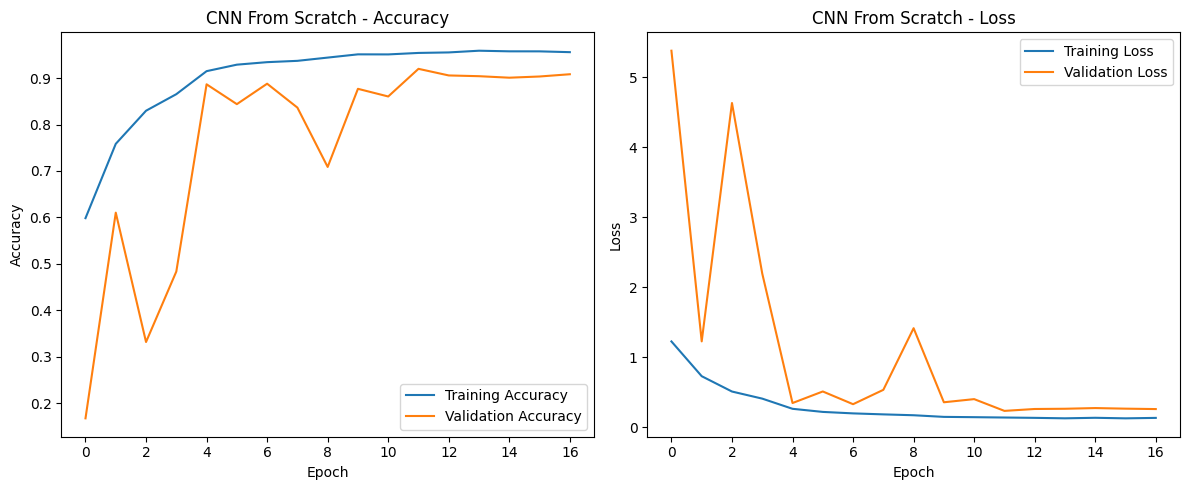

In [ ]:
plot_history(
    cnn_history,
    "CNN From Scratch"
)

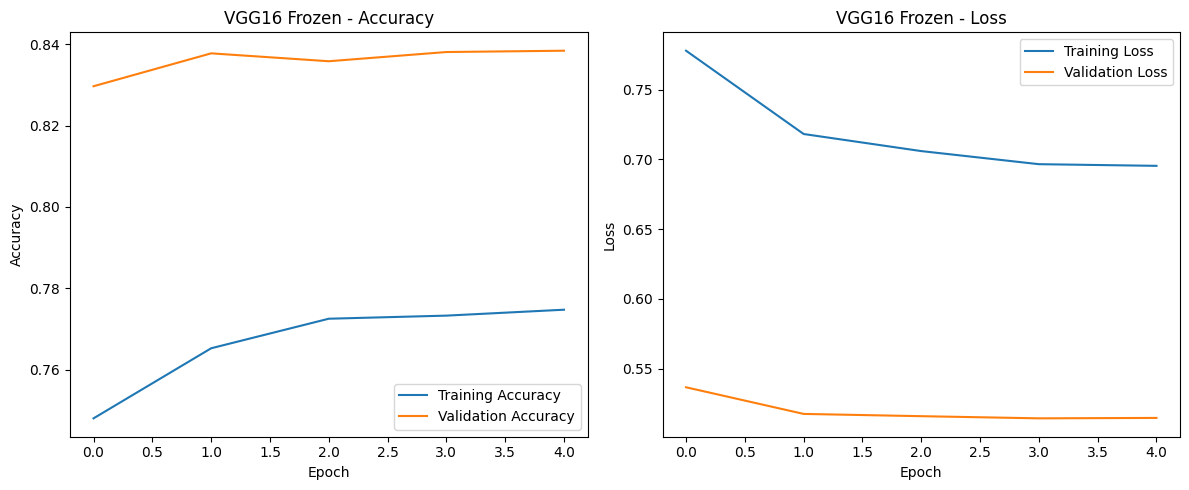

In [ ]:
plot_history(
    vgg_history,
    "VGG16 Frozen"
)

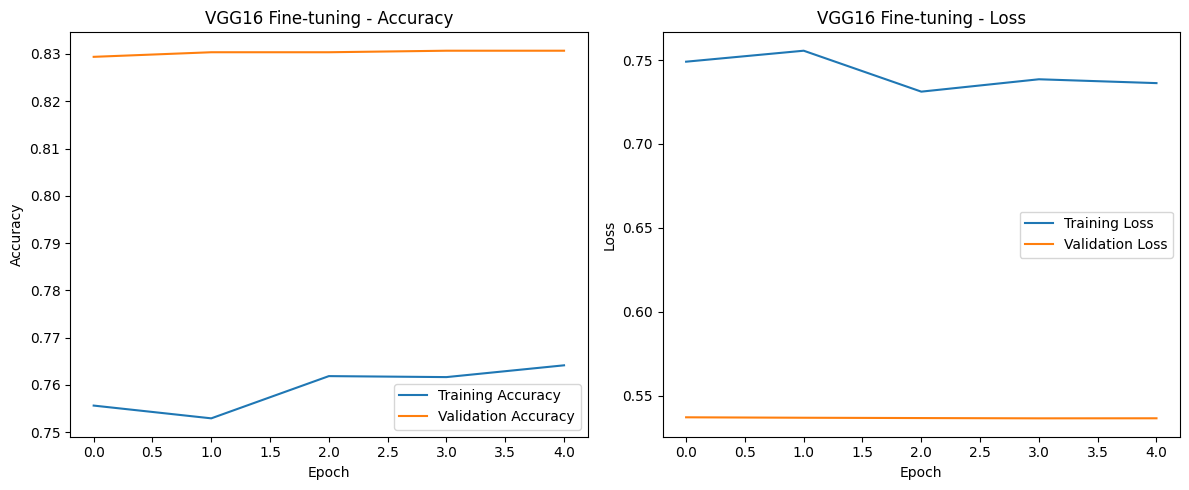

In [ ]:
plot_history(
    vgg_finetune_history,
    "VGG16 Fine-tuning"
)

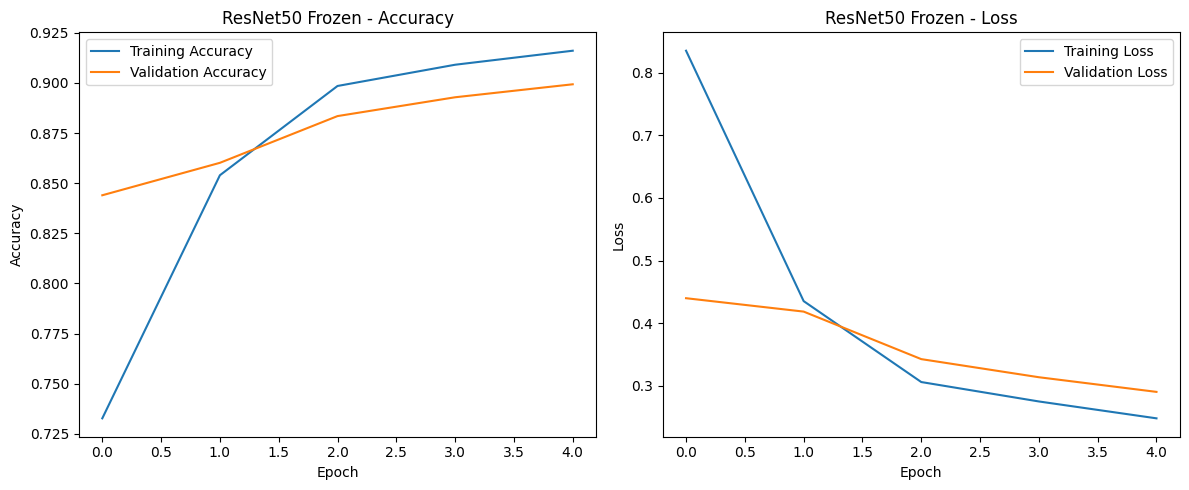

In [ ]:
plot_history(
    resnet_history,
    "ResNet50 Frozen"
)

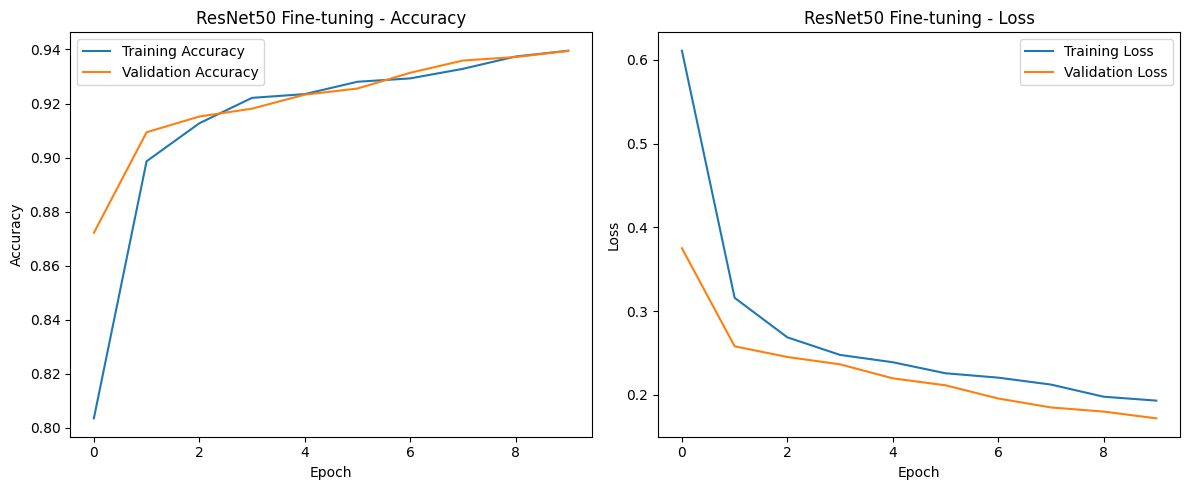

In [ ]:
plot_history(
    resnet_finetune_history,
    "ResNet50 Fine-tuning"
)

In [ ]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    title
):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(14, 12))

    sns.heatmap(
        cm,
        annot=False,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks(
        rotation=90,
        fontsize=7
    )

    plt.yticks(
        rotation=0,
        fontsize=7
    )

    plt.tight_layout()
    plt.show()

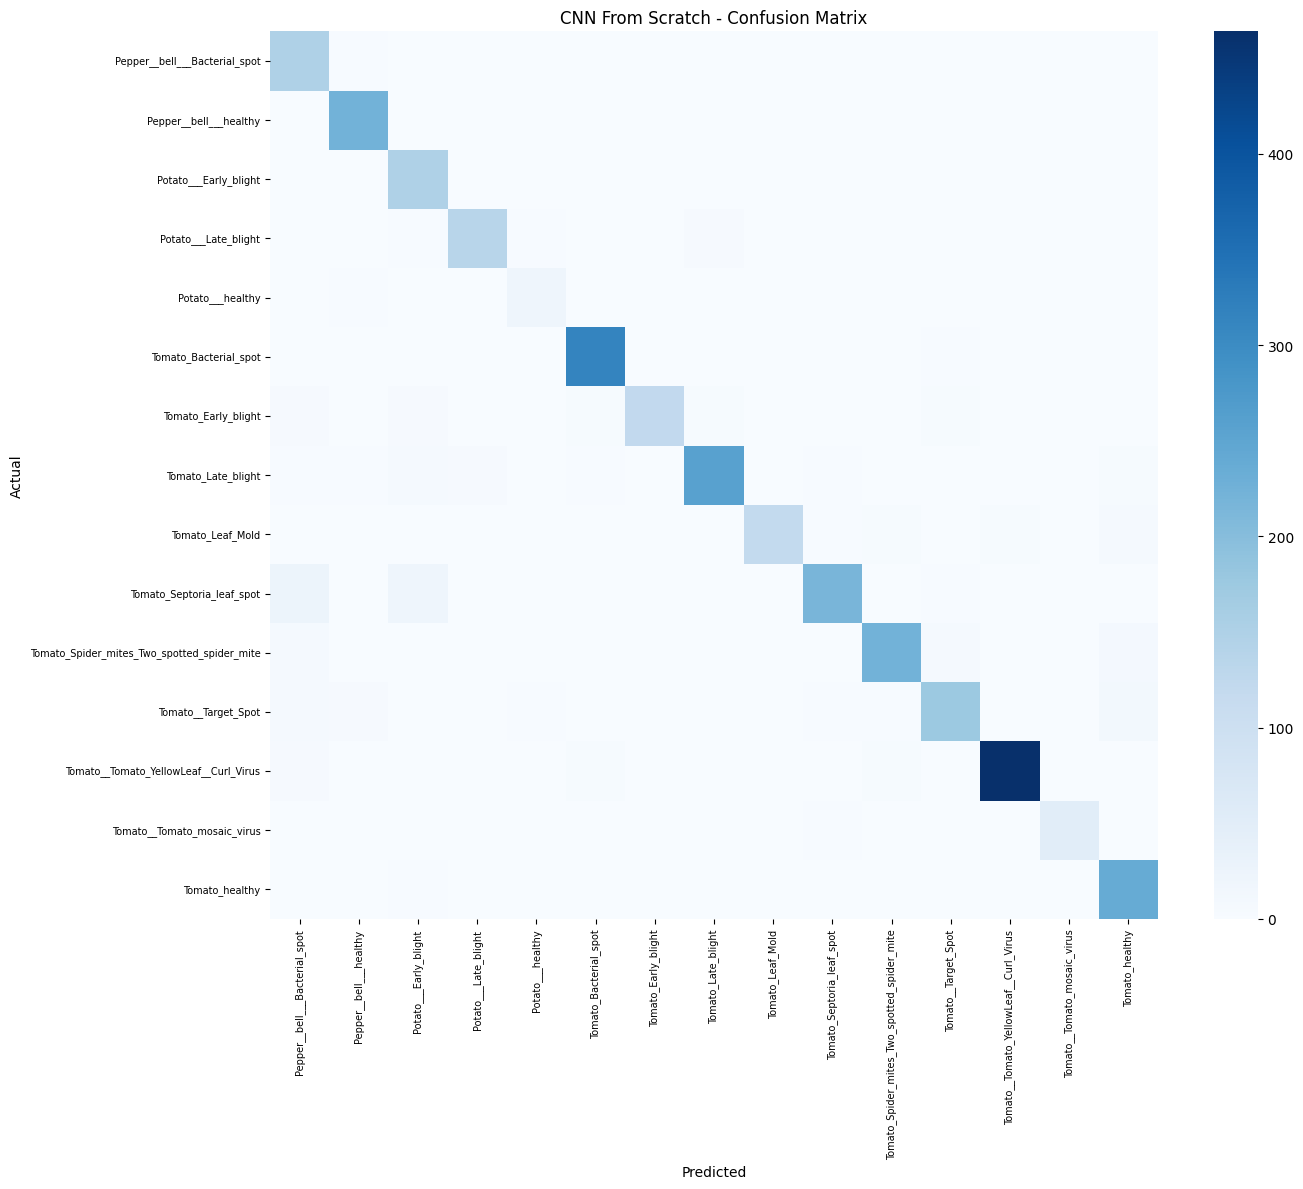

In [ ]:
plot_confusion_matrix(
    cnn_results["y_true"],
    cnn_results["y_pred"],
    "CNN From Scratch - Confusion Matrix"
)

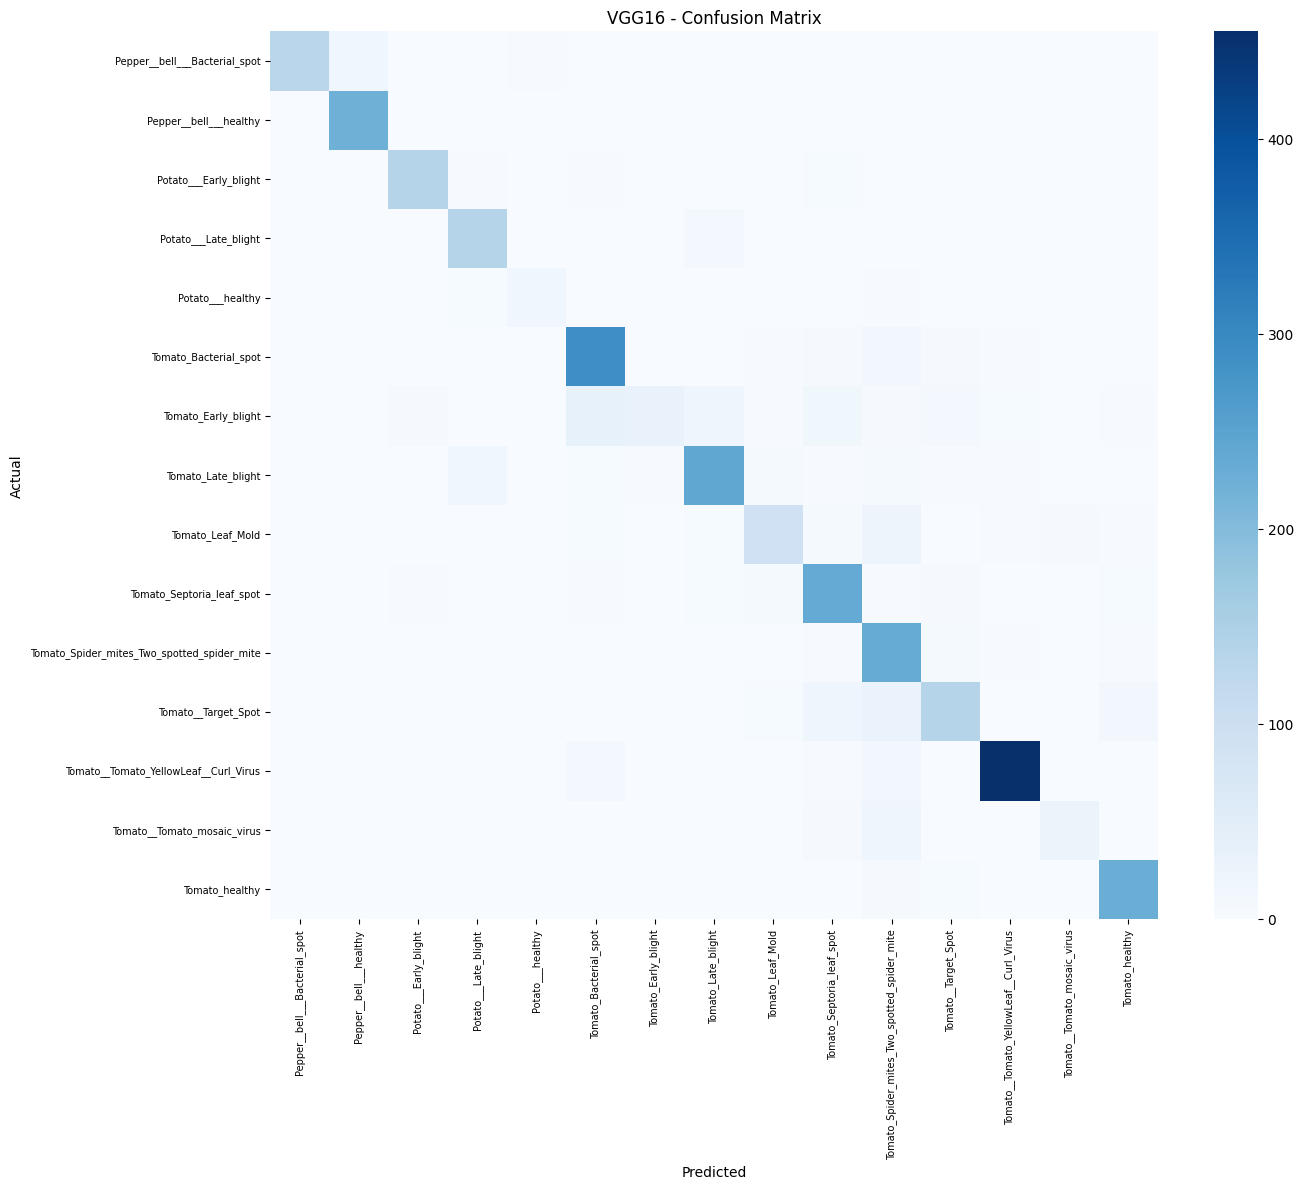

In [ ]:
plot_confusion_matrix(
    vgg_results["y_true"],
    vgg_results["y_pred"],
    "VGG16 - Confusion Matrix"
)

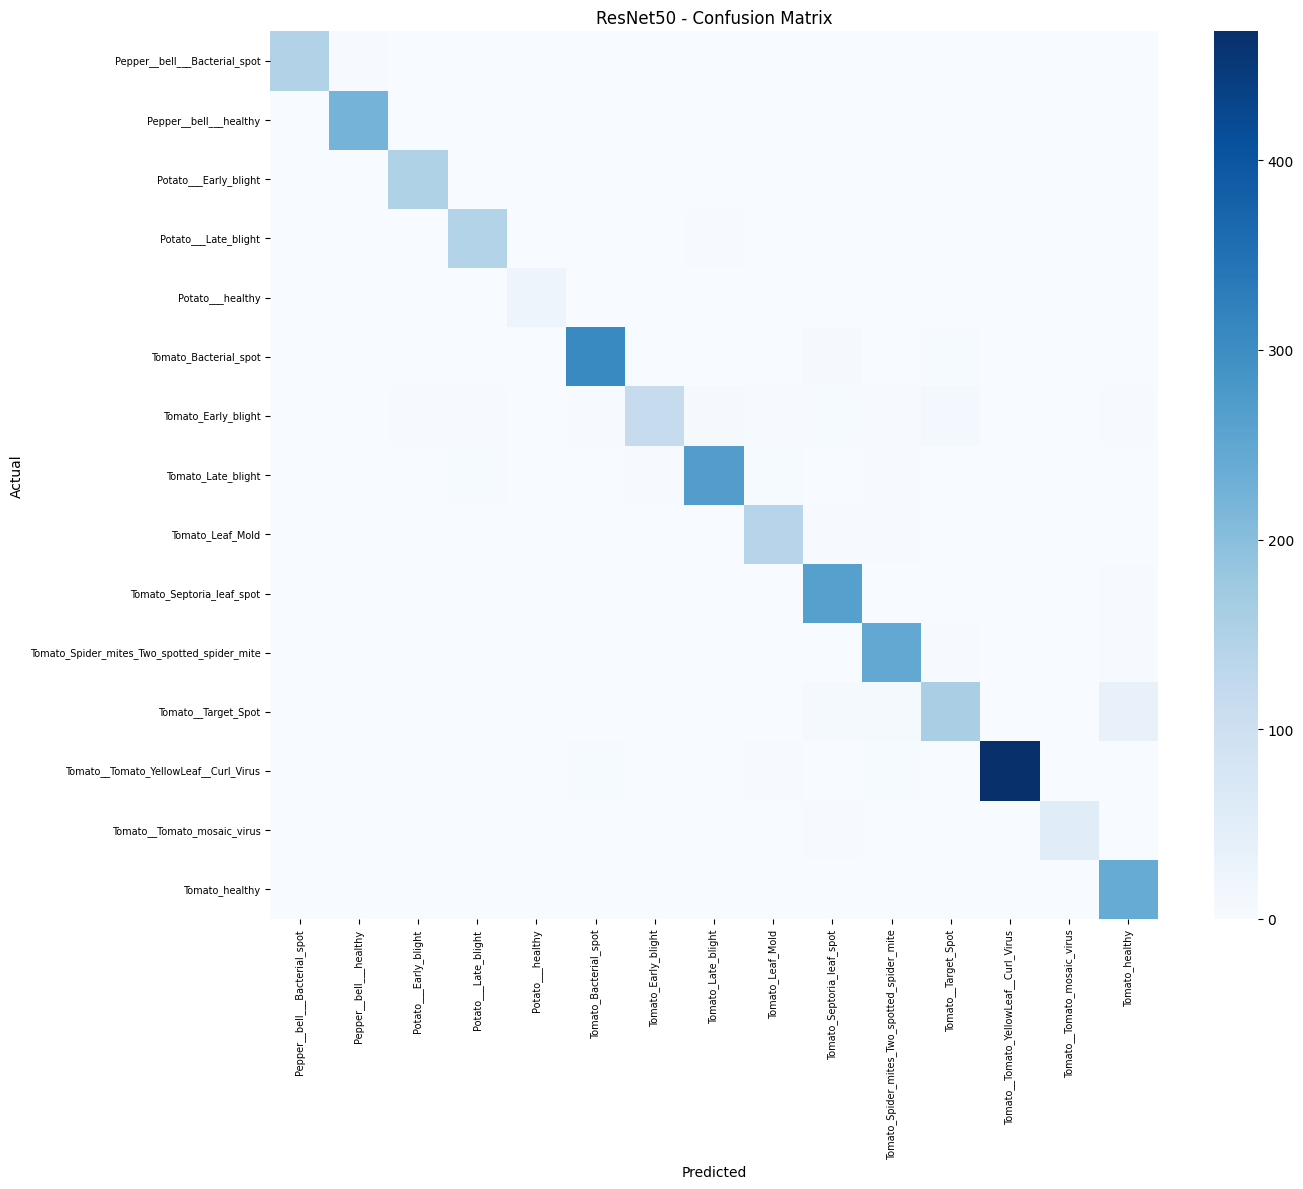

In [ ]:
plot_confusion_matrix(
    resnet_results["y_true"],
    resnet_results["y_pred"],
    "ResNet50 - Confusion Matrix"
)

In [ ]:
print("CNN From Scratch - Classification Report")
print("=" * 60)

print(
    classification_report(
        cnn_results["y_true"],
        cnn_results["y_pred"],
        target_names=class_names,
        zero_division=0
    )
)

CNN From Scratch - Classification Report
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.71      0.99      0.83       151
                     Pepper__bell___healthy       0.93      1.00      0.97       223
                      Potato___Early_blight       0.78      1.00      0.87       150
                       Potato___Late_blight       0.96      0.91      0.94       150
                           Potato___healthy       0.76      0.92      0.83        24
                      Tomato_Bacterial_spot       0.97      0.98      0.98       320
                        Tomato_Early_blight       0.97      0.81      0.88       150
                         Tomato_Late_blight       0.95      0.90      0.92       287
                           Tomato_Leaf_Mold       1.00      0.84      0.91       144
                  Tomato_Septoria_leaf_spot       0.95      0.81      0.87       267
Tomato_Spider_mites_Two

In [ ]:
print("VGG16 Fine-tuned - Classification Report")
print("=" * 60)

print(
    classification_report(
        vgg_results["y_true"],
        vgg_results["y_pred"],
        target_names=class_names,
        zero_division=0
    )
)

VGG16 Fine-tuned - Classification Report
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.98      0.86      0.92       151
                     Pepper__bell___healthy       0.92      1.00      0.96       223
                      Potato___Early_blight       0.93      0.92      0.92       150
                       Potato___Late_blight       0.84      0.91      0.88       150
                           Potato___healthy       0.80      0.67      0.73        24
                      Tomato_Bacterial_spot       0.82      0.90      0.86       320
                        Tomato_Early_blight       0.91      0.21      0.35       150
                         Tomato_Late_blight       0.85      0.84      0.85       287
                           Tomato_Leaf_Mold       0.78      0.65      0.70       144
                  Tomato_Septoria_leaf_spot       0.76      0.88      0.81       267
Tomato_Spider_mites_Two

In [ ]:
print(
    classification_report(
        resnet_results["y_true"],
        resnet_results["y_pred"],
        target_names=class_names,
        zero_division=0
    )
)

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       1.00      0.98      0.99       151
                     Pepper__bell___healthy       0.99      1.00      0.99       223
                      Potato___Early_blight       0.98      0.99      0.99       150
                       Potato___Late_blight       0.95      0.97      0.96       150
                           Potato___healthy       0.96      1.00      0.98        24
                      Tomato_Bacterial_spot       0.98      0.96      0.97       320
                        Tomato_Early_blight       0.97      0.77      0.86       150
                         Tomato_Late_blight       0.96      0.94      0.95       287
                           Tomato_Leaf_Mold       0.93      0.97      0.95       144
                  Tomato_Septoria_leaf_spot       0.92      0.99      0.95       267
Tomato_Spider_mites_Two_spotted_spider_mite       0.93      0.98

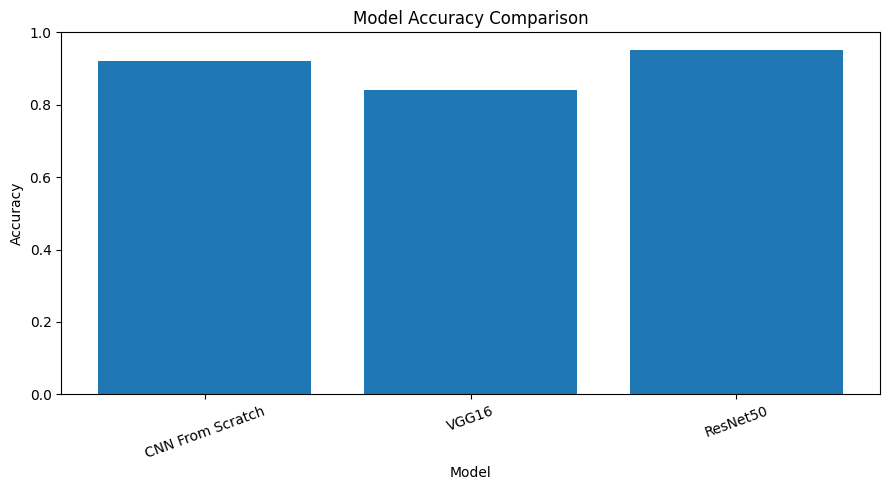

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy"]
)

plt.ylim(0, 1)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

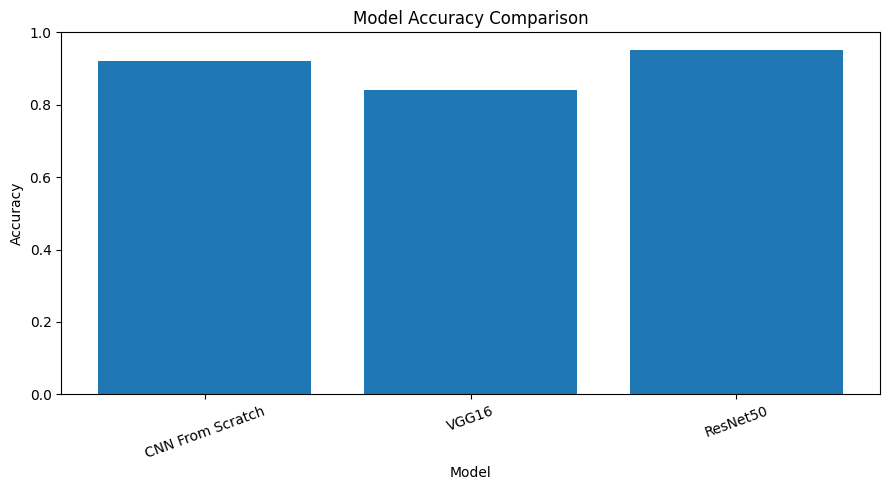

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy"]
)

plt.ylim(0, 1)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

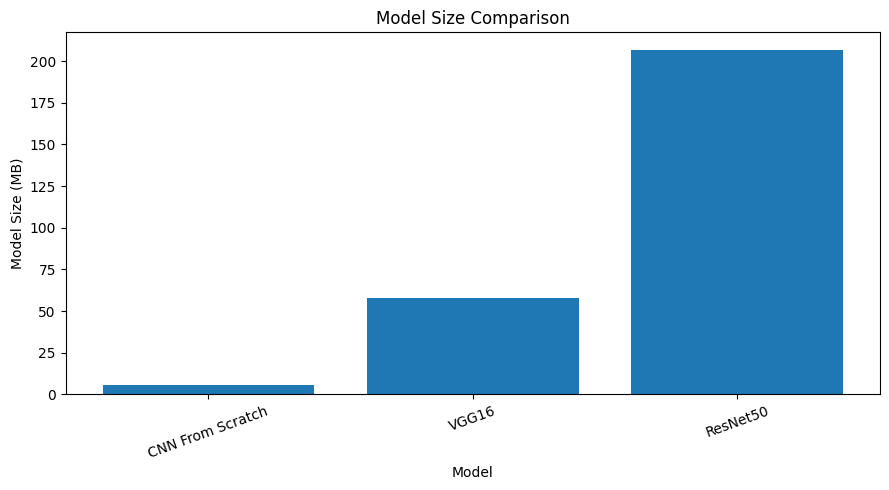

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Model Size (MB)"]
)

plt.ylabel("Model Size (MB)")
plt.xlabel("Model")
plt.title("Model Size Comparison")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [ ]:
def predict_leaf(model, image_path, class_names):

    # Load image
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    # Convert image to array
    image_array = tf.keras.utils.img_to_array(image)

    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Predict
    predictions = model.predict(
        image_array,
        verbose=0
    )[0]

    # Get predicted class
    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]

    # Get confidence
    confidence = predictions[predicted_index]

    # Display image
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )
    plt.axis("off")
    plt.show()

    # Print result
    print("Predicted Disease/Class:", predicted_class)
    print(f"Confidence: {confidence:.2%}")

    return predicted_class, confidence

Testing image: /content/PlantDisease_Split/test/Tomato_Late_blight/fe20bf11-9be6-480c-8c99-b7b391ac9653___GHLB_PS Leaf 44.2 Day 18.jpg


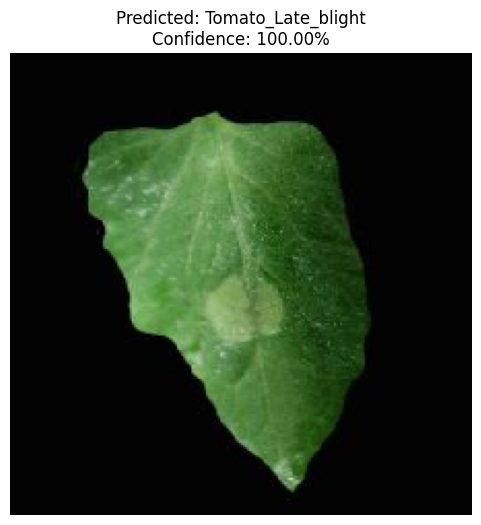

Predicted Disease/Class: Tomato_Late_blight
Confidence: 100.00%


In [ ]:
# Find a test image automatically

image_files = []

for extension in ["*.jpg", "*.JPG", "*.jpeg", "*.JPEG", "*.png", "*.PNG"]:
    image_files.extend(
        glob.glob(
            TEST_DIR + "/**/" + extension,
            recursive=True
        )
    )

sample_image = image_files[0]

print("Testing image:", sample_image)

prediction = predict_leaf(
    resnet_model,
    sample_image,
    class_names
)

Final

In [ ]:
# Final evaluation results

final_results = []

# CNN
final_results.append({
    "Model": "CNN",
    "Strategy": "From Scratch",
    "Accuracy": cnn_results["Accuracy"],
    "Precision": cnn_results["Precision"],
    "Recall": cnn_results["Recall"],
    "F1 Score": cnn_results["F1 Score"],
    "Training Time (min)": cnn_training_time / 60
})

# VGG16
final_results.append({
    "Model": "VGG16",
    "Strategy": "Fine-tuned",
    "Accuracy": vgg_results["Accuracy"],
    "Precision": vgg_results["Precision"],
    "Recall": vgg_results["Recall"],
    "F1 Score": vgg_results["F1 Score"],
    "Training Time (min)": (
        vgg_training_time + vgg_finetune_time
    ) / 60
})

# ResNet50
final_results.append({
    "Model": "ResNet50",
    "Strategy": "Fine-tuned",
    "Accuracy": resnet_results["Accuracy"],
    "Precision": resnet_results["Precision"],
    "Recall": resnet_results["Recall"],
    "F1 Score": resnet_results["F1 Score"],
    "Training Time (min)": (
        resnet_training_time + resnet_finetune_time
    ) / 60
})

final_results_df = pd.DataFrame(final_results)

final_results_df

,Model,Strategy,Accuracy,Precision,Recall,F1 Score,Training Time (min)
0,CNN,From Scratch,0.921840,0.930439,0.921840,0.922430,18.694217
1,VGG16,Fine-tuned,0.841750,0.852390,0.841750,0.831881,14.633910
2,ResNet50,Fine-tuned,0.949823,0.951670,0.949823,0.949004,25.381277


In [ ]:
final_comparison = final_results_df.merge(
    parameter_df,
    on="Model",
    how="left"
).merge(
    size_results,
    on="Model",
    how="left"
)

final_comparison

,Model,Strategy,Accuracy,Precision,Recall,F1 Score,Training Time (min),Total Parameters,Trainable Parameters,Non-trainable Parameters,Model Size (MB)
0,CNN,From Scratch,0.921840,0.930439,0.921840,0.922430,18.694217,NaN,NaN,NaN,NaN
1,VGG16,Fine-tuned,0.841750,0.852390,0.841750,0.831881,14.633910,14849871.0,7214607.0,7635264.0,57.789865
2,ResNet50,Fine-tuned,0.949823,0.951670,0.949823,0.949004,25.381277,24116111.0,14978575.0,9137536.0,206.949823


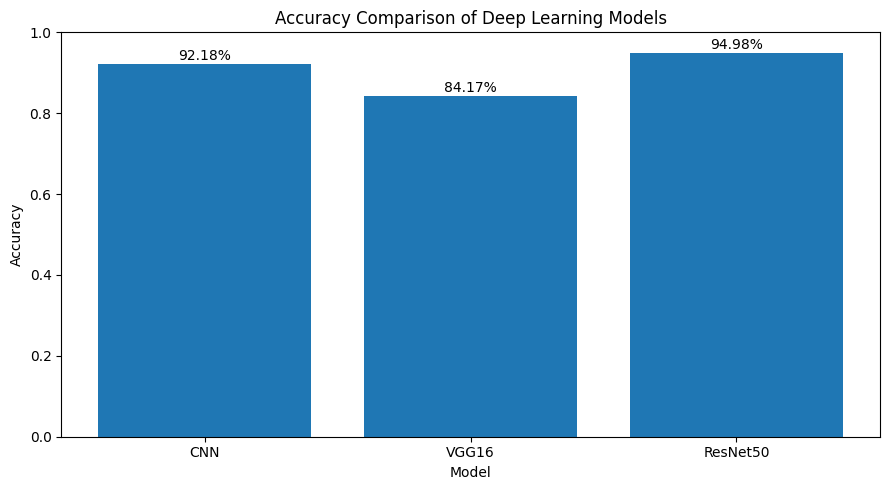

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy"]
)

plt.ylim(0, 1)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Accuracy Comparison of Deep Learning Models")

for bar, accuracy in zip(
    bars,
    final_comparison["Accuracy"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

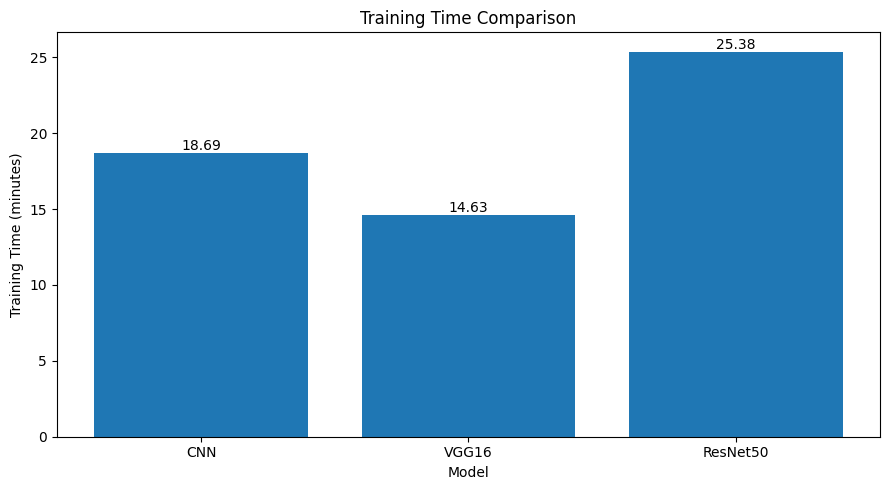

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["Training Time (min)"]
)

plt.ylabel("Training Time (minutes)")
plt.xlabel("Model")
plt.title("Training Time Comparison")

for bar, value in zip(
    bars,
    final_comparison["Training Time (min)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

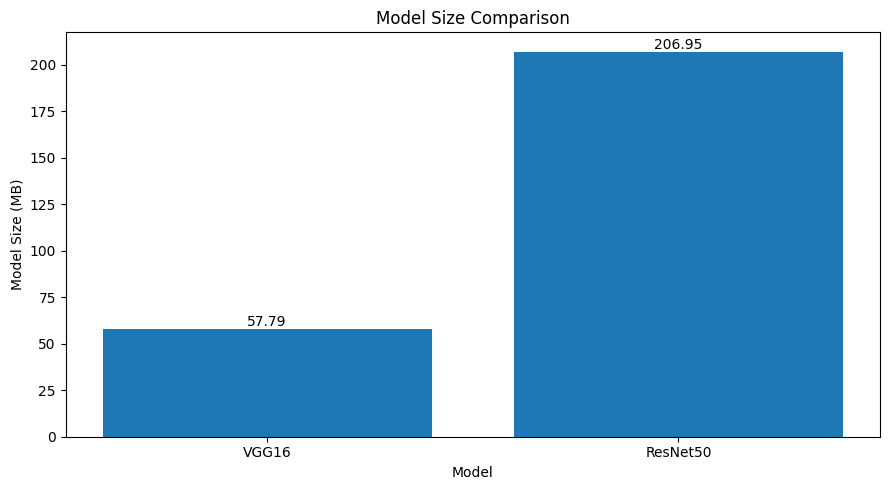

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    final_comparison["Model"],
    final_comparison["Model Size (MB)"]
)

plt.ylabel("Model Size (MB)")
plt.xlabel("Model")
plt.title("Model Size Comparison")

for bar, value in zip(
    bars,
    final_comparison["Model Size (MB)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

comparison_metrics = final_comparison[
    ["Model"] + metrics
]

comparison_metrics

,Model,Accuracy,Precision,Recall,F1 Score
0,CNN,0.921840,0.930439,0.921840,0.922430
1,VGG16,0.841750,0.852390,0.841750,0.831881
2,ResNet50,0.949823,0.951670,0.949823,0.949004


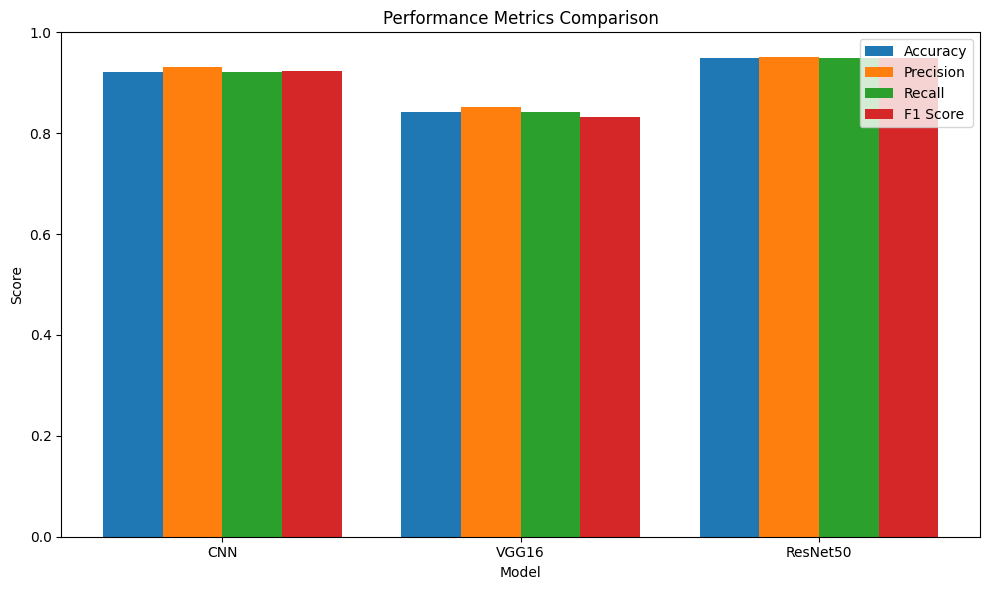

In [ ]:
plt.figure(figsize=(10, 6))

x = np.arange(len(final_comparison["Model"]))
width = 0.2

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        final_comparison[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    final_comparison["Model"]
)

plt.ylim(0, 1)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Performance Metrics Comparison")
plt.legend()

plt.tight_layout()
plt.show()